# How much did the 2021–23 energy price shock drive UK inflation?

**Question.** How much of the 2021–23 rise in UK inflation came from energy, and how long did wholesale gas price rises take to reach household bills (the Ofgem price cap) and then CPI?

**Data (monthly, January 2015 to latest).**

| Source | Series | Use |
|---|---|---|
| ONS – *Consumer price inflation time series* (MM23) | CPI all items annual rate (D7G7) and index (D7BT); CPI 04.5 *electricity, gas and other fuels* annual rate, index and weight; core CPI excluding energy, food, alcohol and tobacco | Inflation |
| Ofgem – energy price cap | Typical dual-fuel direct-debit bill, £ per year | Household bills |
| FRED (St. Louis Fed) | European natural gas `PNGASEUUSDM`, Brent crude `DCOILBRENTEU`, USD/GBP `DEXUSUK`, HICP 04.5 for France and Germany | Wholesale prices, currency, comparison |
| Bank of England | Bank Rate `IUDBEDR` | Monetary policy response |
| Our World in Data (Ember / Energy Institute) | Share of electricity generated by gas and nuclear | Nuclear extension |

**Headline findings**

1. **Pass-through lag:** wholesale gas price changes took about **6 months** to show up in the Ofgem price cap, and bill changes reached CPI in the same month. A sustained 10% rise in wholesale gas lifted CPI energy prices by about **2%** within a year.
2. **Energy's contribution and the Energy Price Guarantee:** household energy added up to **3.5 percentage points** to inflation (October 2022), about a third of the 11.1% peak. Without the £2,500 Energy Price Guarantee, CPI would have peaked at about **14.0%**, and a typical household saved about **£900**.
3. **Policy response:** CPI went above the 2% target in May 2021, **7 months** before the first Bank Rate rise (December 2021). The real Bank Rate fell to **−8.8%**.

## 1. Set-up

In [1]:
import os, io, zipfile, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import requests

try:
    from IPython.display import display
except ImportError:          # running outside Jupyter
    display = print

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 120)

START = "2015-01-01"                     # analysis window starts here
GITHUB_USER = "pj2004m-sys"
REPO = "UK-Energy-Inflation"           # GitHub repository name
NOTEBOOK = "uk_energy_inflation.ipynb"  # file name inside the repository

DATA_DIR, CHART_DIR = "data", "charts"
os.makedirs(DATA_DIR, exist_ok=True)
os.makedirs(CHART_DIR, exist_ok=True)

HEADERS = {"User-Agent": ("Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 "
                         "(KHTML, like Gecko) Chrome/124.0.0.0 Safari/537.36"),
           "Accept": "text/csv,application/octet-stream,text/plain,*/*",
           "Accept-Language": "en-GB,en;q=0.9"}

# Key dates marked on the charts
EVENTS = {pd.Timestamp("2022-02-01"): "Russia invades Ukraine",
          pd.Timestamp("2022-10-01"): "Energy Price Guarantee"}
EPG_START, EPG_END, EPG_LEVEL = pd.Timestamp("2022-10-01"), pd.Timestamp("2023-06-01"), 2500

# One colour per series, used the same way on every chart
C = {"headline": "#2a78d6", "energy": "#eb6834", "gas": "#1baf7a", "cap": "#6250d6",
     "core": "#8a8984", "bank": "#d55181", "ink": "#0b0b0b", "ink2": "#52514e", "grid": "#e6e5e1"}

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": C["ink2"], "axes.labelcolor": C["ink2"],
    "xtick.color": C["ink2"], "ytick.color": C["ink2"],
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": C["grid"], "grid.linewidth": 0.8,
    "lines.linewidth": 2, "legend.frameon": False,
})

FINDINGS = {}    # every headline number is stored here and reused in the write-up and README
print("Set-up complete. pandas", pd.__version__)

Set-up complete. pandas 3.0.5


## 2. Collect the data

Each dataset is downloaded from its source and saved to `data/`; if a download fails, a previously saved copy is used.

In [2]:
FAILED_HOSTS = set()   # a site that has timed out once is not tried again in this run


def find_uploaded_csv(column):
    """Find a CSV uploaded under any name (e.g. 'fredgraph (2).csv') whose header row names `column`."""
    for cand in all_uploaded_csvs():
        try:
            with open(cand, encoding="utf-8-sig", errors="ignore") as fh:
                if column.upper() in fh.readline().upper():
                    return cand
        except OSError:
            pass
    return None


def all_uploaded_csvs():
    """Every CSV in the working folder and its sub-folders (Colab's Files panel), skipping sample_data."""
    import glob
    return sorted(p for p in glob.glob("**/*.csv", recursive=True) if not p.startswith("sample_data"))


def fetch(urls, filename, alt_names=(), attempts=2):
    """Return the path of data/filename.
    1. If the file is already saved (a previous download, or uploaded by hand into data/ or the
       main Files folder, under `filename` or any of `alt_names`), use it.
    2. Otherwise download it, trying each URL up to `attempts` times."""
    import time, shutil
    from urllib.parse import urlparse
    urls = [urls] if isinstance(urls, str) else list(urls)
    path = os.path.join(DATA_DIR, filename)
    for name in (filename, *alt_names):
        for cand in (os.path.join(DATA_DIR, name), name):
            if os.path.isfile(cand) and os.path.getsize(cand) > 50:
                if os.path.abspath(cand) != os.path.abspath(path):
                    shutil.copy(cand, path)
                print(f"Using saved file   {cand}")
                return path
    last_error = None
    for attempt in range(attempts):
        for url in urls:
            host = urlparse(url).netloc
            if host in FAILED_HOSTS:
                continue
            try:
                r = requests.get(url, headers=HEADERS, timeout=(15, 60 + 30 * attempt))
                r.raise_for_status()
                if len(r.content) < 50 or r.content.lstrip()[:15].lower().startswith((b"<!doctype", b"<html")):
                    raise ValueError("server returned a web page, not a data file")
                with open(path, "wb") as f:
                    f.write(r.content)
                print(f"Downloaded         {filename:<34} {len(r.content)/1e6:6.2f} MB")
                return path
            except Exception as e:
                last_error = e
                if attempt == attempts - 1:
                    FAILED_HOSTS.add(host)
        if attempt < attempts - 1 and not all(urlparse(u).netloc in FAILED_HOSTS for u in urls):
            print(f"  {filename}: attempt {attempt + 1} failed ({type(last_error).__name__}), retrying...")
            time.sleep(5)
    found = [p for p in all_uploaded_csvs() if not p.startswith(DATA_DIR + os.sep)] or ["(none)"]
    raise RuntimeError(f"Could not download {filename} ({type(last_error).__name__ if last_error else 'site unavailable'}).\n"
                       f"Download it in a browser from {urls[-1]} and upload it to the Files panel, then re-run.\n"
                       f"Uploaded CSV files the notebook can see: {', '.join(found)}")


def monthly_mean(s):
    """Average any daily/weekly series to calendar months, dated on the 1st ('MS' = month start)."""
    return s.resample("MS").mean()

### 2.1 ONS consumer price inflation (MM23)

MM23 is a wide file: one column per series, with the series title in row 1, its four-character code (CDID) in row 2, a few metadata rows, and then annual, quarterly and monthly observations mixed together. Only the monthly rows (labelled like `2022 OCT`) are kept, and each series is selected by CDID, with a title search as a fallback.

In [3]:
MM23_URL = ("https://www.ons.gov.uk/file?uri=/economy/inflationandpriceindices/"
            "datasets/consumerpriceindices/current/mm23.csv")
mm23_raw = pd.read_csv(fetch(MM23_URL, "mm23.csv"), header=None, dtype=str, low_memory=False)

labels = mm23_raw[0].fillna("").str.strip()
cdid_row = labels[labels.str.upper() == "CDID"].index[0]
catalogue = pd.DataFrame({"title": mm23_raw.iloc[0, 1:].fillna("").str.strip().values,
                          "cdid": mm23_raw.iloc[cdid_row, 1:].fillna("").str.strip().values},
                         index=mm23_raw.columns[1:])

is_month = labels.str.match(r"^\d{4} [A-Za-z]{3}$")
is_year = labels.str.match(r"^\d{4}$")
month_index = pd.to_datetime(labels[is_month].str.title(), format="%Y %b")


def mm23(cdid=None, pattern=None, name=None, annual=False):
    """Return one MM23 series (monthly by default). Match on CDID first, then on a regex of the title."""
    col = None
    if cdid and (catalogue.cdid == cdid).any():
        col = catalogue.index[catalogue.cdid == cdid][0]
    elif pattern:
        hits = catalogue.index[catalogue.title.str.upper().str.contains(pattern, regex=True)]
        if len(hits):
            col = hits[0]
    if col is None:
        raise KeyError(f"MM23 series not found: cdid={cdid}, pattern={pattern}")
    print(f"  {name or cdid:<16} {catalogue.at[col, 'cdid']:<5} {catalogue.at[col, 'title'][:90]}")
    if annual:
        vals = pd.to_numeric(mm23_raw.loc[is_year, col], errors="coerce")
        out = pd.Series(vals.values, index=labels[is_year].astype(int).values, name=name).dropna()
        if out.empty:   # some files only fill the monthly rows for weights
            m = pd.Series(pd.to_numeric(mm23_raw.loc[is_month, col], errors="coerce").values, index=month_index.values)
            out = m.dropna().groupby(m.dropna().index.year).first().rename(name)
        return out
    vals = pd.to_numeric(mm23_raw.loc[is_month, col], errors="coerce")
    return pd.Series(vals.values, index=month_index.values, name=name)


ENERGY = r"04\.5\s*:?\s*ELECTRICITY,? GAS"
print("Series selected from MM23:")
cpi_rate    = mm23("D7G7", r"^CPI ANNUAL RATE 00\s*:?\s*ALL ITEMS", "cpi_headline")
cpi_index   = mm23("D7BT", r"^CPI INDEX 00\s*:?\s*ALL ITEMS", "cpi_index")
core_rate   = mm23("DKO8", r"^CPI ANNUAL RATE.*EXCL\w*\.?\s+ENERGY,?\s+FOOD", "cpi_core")
energy_rate = mm23(None, r"^CPI ANNUAL RATE " + ENERGY, "cpi_energy")
energy_idx  = mm23(None, r"^CPI INDEX " + ENERGY, "energy_index")

# Basket weights (parts per 1,000) are published once a year
w_energy = mm23(None, r"^CPI WEIGHTS " + ENERGY, "w_energy", annual=True)
try:   # electricity (04.5.1) + gas (04.5.2): the part of 04.5 that the cap and the EPG cover
    w_elec_gas = (mm23(None, r"^CPI WEIGHTS 04\.5\.1", "w_elec", annual=True)
                  + mm23(None, r"^CPI WEIGHTS 04\.5\.2", "w_gas", annual=True)).dropna()
except KeyError:
    w_elec_gas = w_energy * 0.9
    print("  (electricity/gas class weights not found - assuming they are 90% of 04.5)")

Using saved file   data/mm23.csv
Series selected from MM23:
  cpi_headline     D7G7  CPI ANNUAL RATE 00: ALL ITEMS 2015=100
  cpi_index        D7BT  CPI INDEX 00: ALL ITEMS 2015=100
  cpi_core         DKO8  CPI 12mth: Excluding Energy, food, alcoholic beverages & tobacco 2015=100
  cpi_energy       D7GT  CPI ANNUAL RATE 04.5 : ELECTRICITY, GAS AND OTHER FUELS 2015=100
  energy_index     D7CH  CPI INDEX 04.5 : ELECTRICITY, GAS AND OTHER FUELS 2015=100
  w_energy         CJVF  CPI WEIGHTS 04.5 : ELECTRICITY, GAS AND OTHER FUELS
  w_elec           CJXA  CPI WEIGHTS 04.5.1 : ELECTRICITY
  w_gas            CJXB  CPI WEIGHTS 04.5.2 : GAS


### 2.2 Ofgem price cap

Ofgem publishes the cap as a web page, not a dataset, so the levels are typed in below and saved to `data/ofgem_price_cap.csv`. The figures are the **typical dual-fuel, direct-debit bill per year** for the period that starts on each date. The cap changed every six months until October 2022 and every quarter after that.

Ofgem's "typical household" has changed over time: electricity use was 3,100 kWh up to March 2020, 2,900 kWh from April 2020 and 2,700 kWh from April 2023, and gas use fell from 12,000 to 11,500 kWh in April 2023. The consumption figures are kept in the file; the analysis uses the headline £ figure.

In [4]:
cap_table = pd.DataFrame([
    # date,        cap £/yr, elec kWh, gas kWh
    ("2019-01-01", 1137, 3100, 12000),
    ("2019-04-01", 1254, 3100, 12000),
    ("2019-10-01", 1179, 3100, 12000),
    ("2020-04-01", 1162, 2900, 12000),
    ("2020-10-01", 1042, 2900, 12000),
    ("2021-04-01", 1138, 2900, 12000),
    ("2021-10-01", 1277, 2900, 12000),
    ("2022-04-01", 1971, 2900, 12000),
    ("2022-10-01", 3549, 2900, 12000),
    ("2023-01-01", 4279, 2900, 12000),
    ("2023-04-01", 3280, 2700, 11500),
    ("2023-07-01", 2074, 2700, 11500),
    ("2023-10-01", 1834, 2700, 11500),
    ("2024-01-01", 1928, 2700, 11500),
    ("2024-04-01", 1690, 2700, 11500),
    ("2024-07-01", 1568, 2700, 11500),
    ("2024-10-01", 1717, 2700, 11500),
    ("2025-01-01", 1738, 2700, 11500),
    ("2025-04-01", 1849, 2700, 11500),
    ("2025-07-01", 1720, 2700, 11500),
    ("2025-10-01", 1755, 2700, 11500),
    ("2026-01-01", 1758, 2700, 11500),
    ("2026-04-01", 1641, 2700, 11500),
    ("2026-07-01", 1862, 2700, 11500),
], columns=["date", "cap_gbp", "elec_kwh", "gas_kwh"])
cap_table.to_csv(os.path.join(DATA_DIR, "ofgem_price_cap.csv"), index=False)

cap_table = pd.read_csv(os.path.join(DATA_DIR, "ofgem_price_cap.csv"))   # round-trip, as in the plan
cap_table["date"] = pd.to_datetime(cap_table["date"])
print(cap_table.tail(4).to_string(index=False))

      date  cap_gbp  elec_kwh  gas_kwh
2025-10-01     1755      2700    11500
2026-01-01     1758      2700    11500
2026-04-01     1641      2700    11500
2026-07-01     1862      2700    11500


### 2.3 Wholesale prices and the exchange rate (FRED)

FRED quotes both gas and Brent in **US dollars**. The pound fell sharply against the dollar in 2022, which made the shock bigger in sterling, so we convert to pounds using `DEXUSUK` (dollars per pound). Gas is then shown in **pence per therm**, the unit the UK market uses: 1 MMBtu = 10 therms.

In [5]:
def fred(series_id):
    uploaded = find_uploaded_csv(series_id)     # works whatever the downloaded file is called
    path = fetch(f"https://fred.stlouisfed.org/graph/fredgraph.csv?id={series_id}",
                 f"fred_{series_id}.csv", alt_names=[uploaded] if uploaded else [])
    raw = pd.read_csv(path)
    s = pd.Series(pd.to_numeric(raw.iloc[:, 1], errors="coerce").values,   # FRED marks gaps with "."
                  index=pd.to_datetime(raw.iloc[:, 0]), name=series_id).dropna()
    return s

gas_usd = monthly_mean(fred("PNGASEUUSDM"))     # $ per MMBtu, already monthly
brent_usd = monthly_mean(fred("DCOILBRENTEU"))  # $ per barrel, daily -> monthly average
usd_per_gbp = monthly_mean(fred("DEXUSUK"))     # $ per £, daily -> monthly average

gas_p_therm = (gas_usd / usd_per_gbp * 10).rename("gas_p_therm")   # $/MMBtu -> £/MMBtu -> p/therm
brent_gbp = (brent_usd / usd_per_gbp).rename("brent_gbp")

Using saved file   data/fred_PNGASEUUSDM.csv
Using saved file   data/fred_DCOILBRENTEU.csv
Using saved file   data/fred_DEXUSUK.csv


### 2.4 Bank Rate (Bank of England)

If the Bank of England database refuses the automated request, the list of Bank Rate decisions below (to August 2025) is used instead.

In [6]:
BOE_URL = ("https://www.bankofengland.co.uk/boeapps/database/_iadb-fromshowcolumns.asp?csv.x=yes"
           "&Datefrom=01/Jan/2014&Dateto=now&SeriesCodes=IUDBEDR&CSVF=TN&UsingCodes=Y&VPD=Y&VFD=N")

BANK_RATE_DECISIONS = [  # fallback only - effective date, new rate (%)
    ("2009-03-05", 0.50), ("2016-08-04", 0.25), ("2017-11-02", 0.50), ("2018-08-02", 0.75),
    ("2020-03-11", 0.25), ("2020-03-19", 0.10), ("2021-12-16", 0.25), ("2022-02-03", 0.50),
    ("2022-03-17", 0.75), ("2022-05-05", 1.00), ("2022-06-16", 1.25), ("2022-08-04", 1.75),
    ("2022-09-22", 2.25), ("2022-11-03", 3.00), ("2022-12-15", 3.50), ("2023-02-02", 4.00),
    ("2023-03-23", 4.25), ("2023-05-11", 4.50), ("2023-06-22", 5.00), ("2023-08-03", 5.25),
    ("2024-08-01", 5.00), ("2024-11-07", 4.75), ("2025-02-06", 4.50), ("2025-05-08", 4.25),
    ("2025-08-07", 4.00)]

try:
    boe = pd.read_csv(fetch(BOE_URL, "boe_bank_rate.csv"))
    assert boe.shape[1] >= 2 and "DATE" in str(boe.columns[0]).upper(), "unexpected file layout"
    bank_daily = pd.Series(pd.to_numeric(boe.iloc[:, 1], errors="coerce").values,
                           index=pd.to_datetime(boe.iloc[:, 0], format="mixed", dayfirst=True),
                           name="bank_rate").dropna().sort_index()
except Exception as e:
    print(f"Bank of England download not usable ({e}).\n"
          "Using the typed-in decision list instead (ends Aug 2025).")
    d = pd.DataFrame(BANK_RATE_DECISIONS, columns=["date", "rate"])
    d["date"] = pd.to_datetime(d["date"])
    bank_daily = (d.set_index("date")["rate"]
                  .reindex(pd.date_range(d.date.min(), "2025-10-31", freq="D")).ffill().rename("bank_rate"))
    bank_daily.to_frame().to_csv(os.path.join(DATA_DIR, "boe_bank_rate_fallback.csv"))

bank_rate = monthly_mean(bank_daily)

Using saved file   data/boe_bank_rate.csv


### 2.5 Extension data: France and Germany, and the electricity mix

These two datasets are only used in Section 9; if either is unavailable, that part is skipped.

* **HICP 04.5 for France and Germany** comes from FRED, which republishes Eurostat's harmonised index. The UK's own CPI is its harmonised index, so the series are comparable.
* **Generation mix**: the government's *Energy Trends* table changes its file address every quarter, which would break an automatic download. We use Our World in Data's copy of the Ember / Energy Institute series instead. It has a stable address and covers all three countries.

In [7]:
try:
    hicp_fr = fred("CP0450FRM086NEST").pipe(monthly_mean)
    hicp_de = fred("CP0450DEM086NEST").pipe(monthly_mean)
    eu_energy = pd.DataFrame({"France": hicp_fr.pct_change(12) * 100,
                              "Germany": hicp_de.pct_change(12) * 100})
except Exception as e:
    eu_energy = None
    print("France/Germany HICP not available - comparison will be skipped.", e)

try:
    OWID_URL = "https://ourworldindata.org/grapher/share-elec-by-source.csv?v=1&csvType=full&useColumnShortNames=false"
    mix_raw = pd.read_csv(fetch(OWID_URL, "owid_share_elec_by_source.csv"))
    gas_col = next(c for c in mix_raw.columns if c.lower().startswith("gas"))
    nuc_col = next(c for c in mix_raw.columns if c.lower().startswith("nuclear"))
    mix = (mix_raw[mix_raw["Entity"].isin(["United Kingdom", "France", "Germany"])]
           .rename(columns={gas_col: "gas_share", nuc_col: "nuclear_share"})
           [["Entity", "Year", "gas_share", "nuclear_share"]])
    print("Generation mix columns used:", gas_col, "|", nuc_col)
except Exception as e:
    mix = None
    print("Generation mix not available - nuclear chart will be skipped.", e)

Using saved file   data/fred_CP0450FRM086NEST.csv
Using saved file   data/fred_CP0450DEM086NEST.csv
Using saved file   data/owid_share_elec_by_source.csv
Generation mix columns used: Gas | Nuclear


## 3. Clean and merge

All series are put on the same calendar: the **first day of each month** (`'MS'`). This matters because pandas' older `'M'` code dates months on their *last* day, and mixing the two silently breaks a merge. The price cap only changes every three to six months, so it is forward-filled to give every month a value. The household bill is the cap, except from October 2022 to June 2023, when the Energy Price Guarantee held it at £2,500.

In [8]:
months = pd.date_range(START, cpi_rate.dropna().index.max(), freq="MS")

cap_monthly = (cap_table.set_index("date")["cap_gbp"]
               .reindex(pd.date_range(cap_table.date.min(), months.max(), freq="MS")).ffill())

df = pd.concat([cpi_rate, core_rate, energy_rate, cpi_index, energy_idx,
                gas_p_therm, brent_gbp, cap_monthly.rename("cap_gbp"), bank_rate], axis=1)
df = df.reindex(months)
df.index.name = "date"

epg_months = (df.index >= EPG_START) & (df.index <= EPG_END)
df["bill_gbp"] = df["cap_gbp"]
df.loc[epg_months, "bill_gbp"] = np.minimum(df.loc[epg_months, "cap_gbp"], EPG_LEVEL)

# Gas and Brent are published faster than CPI; keep the panel to months where CPI exists
df.to_csv(os.path.join(DATA_DIR, "merged_monthly.csv"))
print(f"Merged panel: {df.index.min():%b %Y} to {df.index.max():%b %Y}, {len(df)} months")
display(df.loc["2022-06-01":"2023-03-01", ["cpi_headline", "cpi_energy", "gas_p_therm", "cap_gbp", "bill_gbp", "bank_rate"]].round(1))

Merged panel: Jan 2015 to Sep 2026, 141 months


,cpi_headline,cpi_energy,gas_p_therm,cap_gbp,bill_gbp,bank_rate
date,,,,,,
2022-06-01,9.4,70.2,267.1,1971.0,1971.0,1.1
2022-07-01,10.1,70.3,426.7,1971.0,1971.0,1.2
2022-08-01,9.9,69.7,584.0,1971.0,1971.0,1.7
2022-09-01,10.1,70.1,487.5,1971.0,1971.0,1.9
2022-10-01,11.1,89.7,183.6,3549.0,2500.0,2.2
2022-11-01,10.7,89.0,245.5,3549.0,2500.0,2.9
2022-12-01,10.5,88.7,290.4,3549.0,2500.0,3.2
2023-01-01,10.1,89.5,162.5,4279.0,2500.0,3.5
2023-02-01,10.4,88.6,138.5,4279.0,2500.0,4.0


## 4. Timeline: from wholesale gas to bills to inflation

Wholesale gas, the price cap and CPI are in different units, so the chart avoids a second y-axis, which makes it easy to read the lines wrongly. The top panel shows **prices indexed to January 2019 = 100** (the month the cap started). The lower panels show **annual inflation rates**: energy CPI gets its own panel because its scale (tens of per cent) would flatten headline CPI.

Saved charts/01_timeline.png


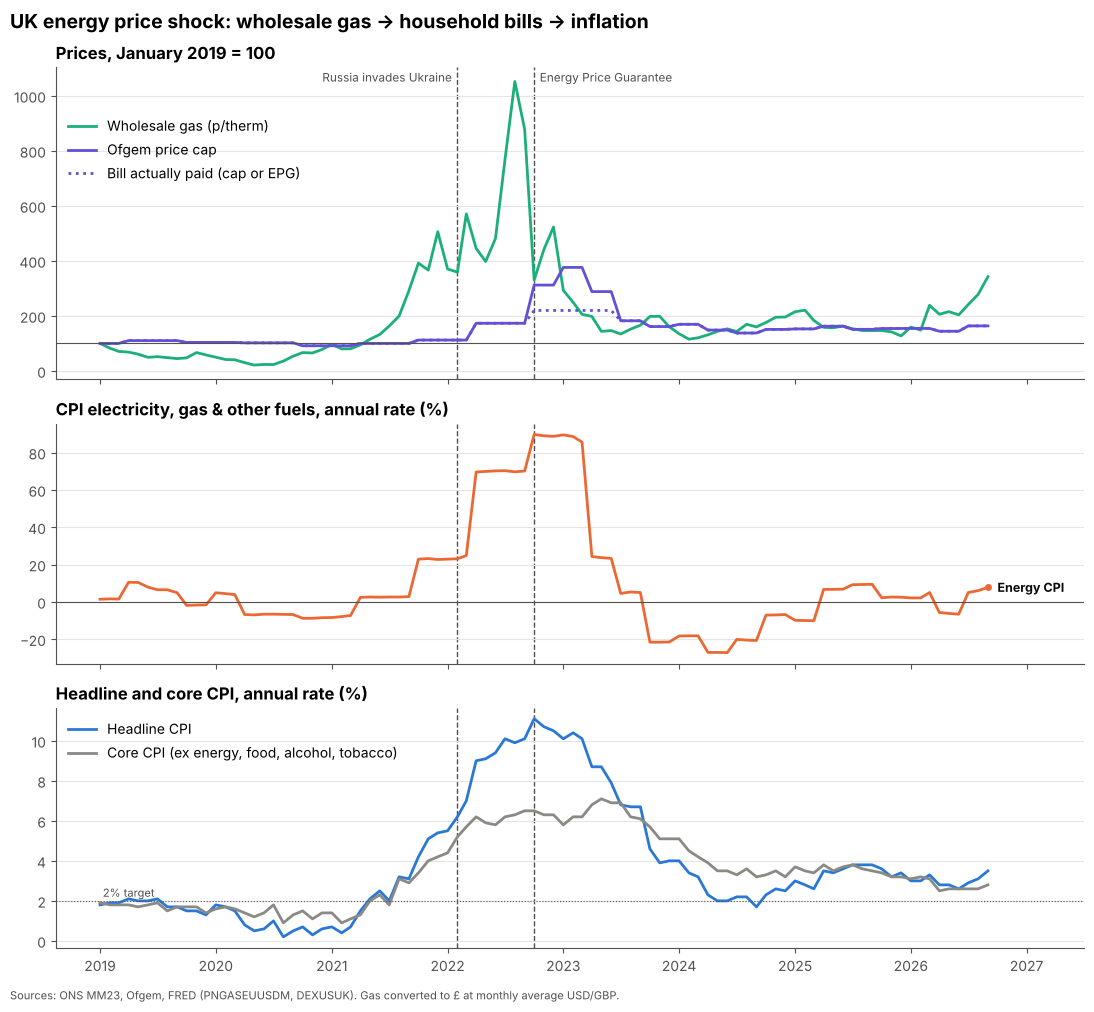

Wholesale gas peaked in Aug 2022 at 10.5x its Jan 2019 level; the cap peaked at 3.8x.
Energy CPI peaked at 89.7% (Oct 2022); headline CPI peaked at 11.1% (Oct 2022).


In [9]:
def mark_events(ax, text=False):
    """Dashed lines for the key dates; the first label sits left of its line, the second right."""
    for i, (d, label) in enumerate(EVENTS.items()):
        ax.axvline(d, color=C["ink2"], lw=1, ls="--", zorder=0)
        if text:
            ax.annotate(label, (d, 1), xycoords=("data", "axes fraction"), xytext=(-4 if i == 0 else 4, -2),
                        textcoords="offset points", va="top", ha="right" if i == 0 else "left",
                        fontsize=8.5, color=C["ink2"])

def end_labels(ax, items, min_gap=0.07):
    """Label each line at its last point; nudge labels apart so they never overlap.
    items = [(series, text, colour), ...]; min_gap is a fraction of the y-axis range."""
    lo, hi = ax.get_ylim()
    gap = (hi - lo) * min_gap
    pts = sorted([(s.dropna().index[-1], s.dropna().iloc[-1], t, c) for s, t, c in items], key=lambda p: p[1])
    placed = []
    for x, yv, t, c in pts:
        ypos = max(yv, placed[-1] + gap) if placed else yv
        placed.append(ypos)
        ax.plot(x, yv, "o", ms=4, color=c)
        ax.annotate(t, (x, yv), xytext=(x + pd.DateOffset(months=1), ypos), textcoords="data",
                    va="center", fontsize=9, color=C["ink"], fontweight="bold")

def end_label(ax, s, text, color):
    end_labels(ax, [(s, text, color)])

def save(fig, name):
    path = os.path.join(CHART_DIR, name)
    fig.savefig(path, facecolor="white")
    print("Saved", path)

base = pd.Timestamp("2019-01-01")
idx = pd.DataFrame({"Wholesale gas (p/therm)": df.gas_p_therm / df.at[base, "gas_p_therm"] * 100,
                    "Ofgem price cap": df.cap_gbp / df.at[base, "cap_gbp"] * 100,
                    "Bill actually paid (cap or EPG)": df.bill_gbp / df.at[base, "bill_gbp"] * 100})
win = slice("2019-01-01", None)

fig, axes = plt.subplots(3, 1, figsize=(11, 10), sharex=True, gridspec_kw={"height_ratios": [1.3, 1, 1]})
ax = axes[0]
ax.plot(idx.loc[win].index, idx.loc[win, "Wholesale gas (p/therm)"], color=C["gas"], label="Wholesale gas (p/therm)")
ax.plot(idx.loc[win].index, idx.loc[win, "Ofgem price cap"], color=C["cap"], label="Ofgem price cap")
ax.plot(idx.loc[win].index, idx.loc[win, "Bill actually paid (cap or EPG)"], color=C["cap"], ls=":", label="Bill actually paid (cap or EPG)")
ax.axhline(100, color=C["ink2"], lw=0.8)
ax.set_title("Prices, January 2019 = 100")
ax.legend(loc="upper left", bbox_to_anchor=(0, 0.88))
mark_events(ax, text=True)

ax = axes[1]
ax.plot(df.loc[win].index, df.loc[win, "cpi_energy"], color=C["energy"])
end_label(ax, df.loc[win, "cpi_energy"], "Energy CPI", C["energy"])
ax.set_xlim(right=df.index.max() + pd.DateOffset(months=10))
ax.axhline(0, color=C["ink2"], lw=0.8)
ax.set_title("CPI electricity, gas & other fuels, annual rate (%)")
mark_events(ax)

ax = axes[2]
ax.plot(df.loc[win].index, df.loc[win, "cpi_headline"], color=C["headline"], label="Headline CPI")
ax.plot(df.loc[win].index, df.loc[win, "cpi_core"], color=C["core"], label="Core CPI (ex energy, food, alcohol, tobacco)")
ax.axhline(2, color=C["ink2"], lw=0.8, ls=":")
ax.annotate("2% target", (df.loc[win].index[0], 2), xytext=(2, 3), textcoords="offset points", fontsize=8, color=C["ink2"])
ax.set_title("Headline and core CPI, annual rate (%)")
ax.legend(loc="upper left")
mark_events(ax)
axes[-1].xaxis.set_major_locator(mdates.YearLocator())
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
fig.suptitle("UK energy price shock: wholesale gas → household bills → inflation", x=0.01, ha="left",
             fontsize=14, fontweight="bold")
fig.text(0.01, -0.01, "Sources: ONS MM23, Ofgem, FRED (PNGASEUUSDM, DEXUSUK). Gas converted to £ at monthly average USD/GBP.",
         fontsize=8, color=C["ink2"])
fig.tight_layout()
save(fig, "01_timeline.png")
plt.show()

FINDINGS["cpi_peak"] = df.cpi_headline.max()
FINDINGS["cpi_peak_date"] = df.cpi_headline.idxmax()
FINDINGS["energy_peak"] = df.cpi_energy.max()
FINDINGS["energy_peak_date"] = df.cpi_energy.idxmax()
FINDINGS["gas_peak_date"] = df.gas_p_therm.idxmax()
FINDINGS["gas_peak_x"] = df.gas_p_therm.max() / df.at[base, "gas_p_therm"]
FINDINGS["cap_peak_x"] = df.cap_gbp.max() / df.at[base, "cap_gbp"]
print(f"Wholesale gas peaked in {FINDINGS['gas_peak_date']:%b %Y} at {FINDINGS['gas_peak_x']:.1f}x its Jan 2019 level; "
      f"the cap peaked at {FINDINGS['cap_peak_x']:.1f}x.")
print(f"Energy CPI peaked at {FINDINGS['energy_peak']:.1f}% ({FINDINGS['energy_peak_date']:%b %Y}); "
      f"headline CPI peaked at {FINDINGS['cpi_peak']:.1f}% ({FINDINGS['cpi_peak_date']:%b %Y}).")

**Interpretation.** Wholesale gas started climbing in mid-2021, well before the invasion of Ukraine, as demand recovered after Covid and European gas storage ran low. The invasion turned a large rise into an extreme one. The cap rose in steps and much less than wholesale gas, because Ofgem averages wholesale costs over several months and wholesale gas is only part of a bill (networks, policy costs and VAT make up the rest). From October 2022 the dotted line splits from the cap: the Energy Price Guarantee held bills at £2,500, which is why energy CPI peaked well below the rise in the cap. Headline CPI followed energy CPI up and then down, while core inflation rose later and more slowly. That pattern suggests the shock fed into wider prices with a delay.

## 5. Pass-through lag

**Method.** Correlating price *levels* can mislead: two series that both trend upwards correlate strongly at almost any lag. So the main test uses **three-month changes in log prices**. This removes the trend, matches the cap's quarterly reset, and stops the huge percentage rises from a low base in 2021 (wholesale gas rose roughly five-fold in a year) from dominating the result. For lag *L* we correlate the change in gas *L* months earlier with the change in the cap today (`gas.shift(L)`), and the same for bills against the CPI energy index. The levels version from the original plan and a year-on-year version are shown alongside for comparison.

* **Gas → cap** uses the cap itself, because that is what Ofgem sets from wholesale costs.
* **Cap → energy CPI** uses the bill actually paid, because during the EPG households paid £2,500 rather than the cap.

Gas → cap             ... Bill → energy CPI            
                levels 3m_changes  ...        3m_changes yoy_changes
lag (months)                       ...                              
0                 0.31      -0.20  ...              0.99        1.00
1                 0.45      -0.03  ...              0.66        0.94
2                 0.60       0.21  ...              0.32        0.88
3                 0.69       0.35  ...             -0.02        0.81
4                 0.76       0.43  ...              0.11        0.73
5                 0.83       0.47  ...              0.24        0.65
6                 0.89       0.53  ...              0.36        0.57
7                 0.87       0.45  ...              0.23        0.46
8                 0.81       0.33  ...              0.09        0.34
9                 0.78       0.24  ...             -0.03        0.22
10                0.75       0.20  ...              0.00        0.11
11                0.67       0.16  ...              0.03        0.00
12                0.62       0.16  ...              0.04       -0.11

[13 rows x 6 columns]

Saved charts/02_pass_through_lags.png


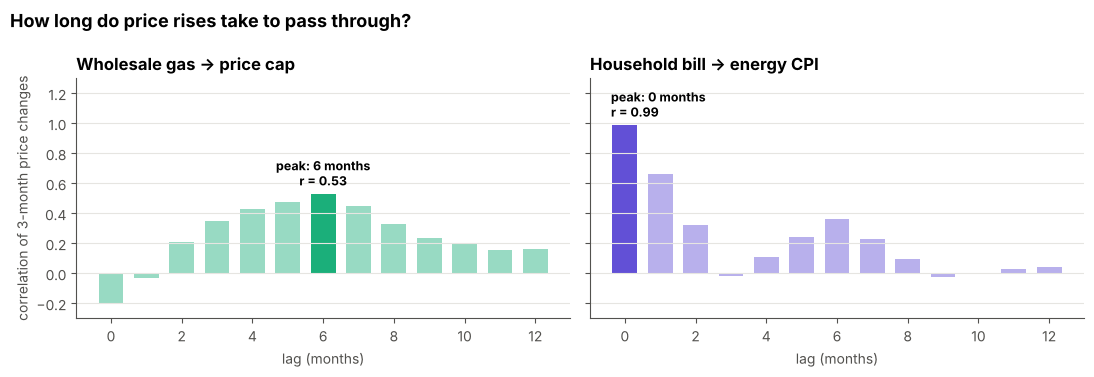

Strongest link: gas -> cap after 6 months; bill -> energy CPI after 0 months.
(Levels give 6 months; year-on-year % changes give 11 months.)


In [10]:
def lag_table(x, y, max_lag=12):
    """corr(x shifted by L months, y) for L = 0..max_lag: on levels, 3-month log changes and year-on-year % changes."""
    d3 = lambda s: np.log(s).diff(3)
    yoy = lambda s: s.pct_change(12) * 100
    return pd.DataFrame({
        "levels":      {L: x.shift(L).corr(y) for L in range(max_lag + 1)},
        "3m_changes":  {L: d3(x).shift(L).corr(d3(y)) for L in range(max_lag + 1)},
        "yoy_changes": {L: yoy(x).shift(L).corr(yoy(y)) for L in range(max_lag + 1)}})

sample = df.loc["2019-01-01":]
lag_gas_cap = lag_table(sample.gas_p_therm, sample.cap_gbp)
lag_cap_cpi = lag_table(sample.bill_gbp, sample.energy_index)

best_gas_cap = int(lag_gas_cap["3m_changes"].idxmax())
best_cap_cpi = int(lag_cap_cpi["3m_changes"].idxmax())
FINDINGS.update(lag_gas_cap=best_gas_cap, lag_cap_cpi=best_cap_cpi,
                r_gas_cap=lag_gas_cap["3m_changes"].max(), r_cap_cpi=lag_cap_cpi["3m_changes"].max(),
                lag_gas_cap_levels=int(lag_gas_cap.levels.idxmax()), lag_gas_cap_yoy=int(lag_gas_cap.yoy_changes.idxmax()))

summary = pd.concat({"Gas → cap": lag_gas_cap, "Bill → energy CPI": lag_cap_cpi}, axis=1)
summary.index.name = "lag (months)"
display(summary.round(2))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, tab, best, title, color in [
        (axes[0], lag_gas_cap, best_gas_cap, "Wholesale gas → price cap", C["gas"]),
        (axes[1], lag_cap_cpi, best_cap_cpi, "Household bill → energy CPI", C["cap"])]:
    bars = ax.bar(tab.index, tab["3m_changes"], color=color, width=0.7, alpha=0.45)
    bars[best].set_alpha(1)
    ax.annotate(f"peak: {best} months\nr = {tab['3m_changes'][best]:.2f}", (best, tab["3m_changes"][best]),
                xytext=(-10 if best == 0 else 0, 6), textcoords="offset points",
                ha="left" if best == 0 else "center", fontsize=9, fontweight="bold")
    ax.set_title(title)
    ax.set_xlabel("lag (months)")
    ax.set_xticks(range(0, 13, 2))
axes[0].set_ylabel("correlation of 3-month price changes")
axes[0].set_ylim(min(0, summary.min().min() - 0.1), 1.3)
fig.suptitle("How long do price rises take to pass through?", x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.tight_layout()
save(fig, "02_pass_through_lags.png")
plt.show()
print(f"Strongest link: gas -> cap after {best_gas_cap} months; bill -> energy CPI after {best_cap_cpi} months.")
print(f"(Levels give {FINDINGS['lag_gas_cap_levels']} months; year-on-year % changes give {FINDINGS['lag_gas_cap_yoy']} months.)")

**Interpretation.** Wholesale gas reaches the cap after about six months (the highlighted bar), and the levels measure from the original plan agrees. Much of this delay is built into the rules: Ofgem sets each cap from wholesale prices observed over an earlier window and announces it weeks before it starts. From bills to CPI there is no delay, because CPI records the price households pay in the month the new tariff applies. The year-on-year measure in the table points to a longer lag (about 11 months). That is mainly because the very large percentage rises from a low base in 2021 dominate it, which is why it isn't used as the main measure.

### 5.1 Distributed-lag model: how much of a gas price rise reaches CPI?

The correlations give the *timing*; a simple regression gives the *size*. We regress the monthly % change in the CPI energy index on the monthly % change in wholesale gas (in £) in the same month and each of the previous 12 months:

$$\Delta \ln \text{EnergyCPI}_t = \alpha + \sum_{L=0}^{12} \beta_L \, \Delta \ln \text{Gas}_{t-L} + \varepsilon_t$$

The sum of the β coefficients is the **cumulative pass-through elasticity**: the % change in household energy prices after 12 months for a 1% change in wholesale gas. The months when the EPG was in force (October 2022 to June 2023) are left out, because policy, not wholesale prices, set bills then.

Sample: Feb 2016-Sep 2026, n = 119, R² = 0.29
Cumulative 12-month pass-through elasticity: 0.20 (s.e. 0.06)
=> a sustained 10% rise in wholesale gas raises CPI energy prices by about 2.0% within a year.


,beta,se,cumulative
lag (months),,,
0,-0.019,0.025,-0.019
1,0.040,0.026,0.021
2,-0.008,0.026,0.013
3,-0.050,0.026,-0.037
4,0.081,0.026,0.045
5,0.001,0.026,0.045
6,0.053,0.026,0.099
7,0.047,0.028,0.146
8,-0.024,0.028,0.122


Saved charts/03_distributed_lag.png


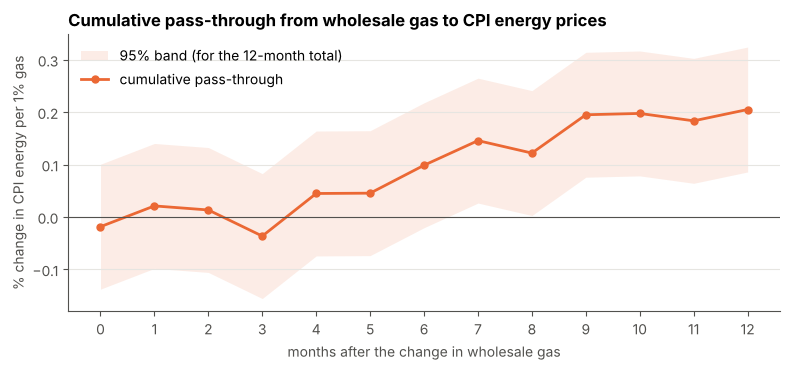

In [11]:
y = np.log(df.energy_index).diff().mul(100).rename("y")
g = np.log(df.gas_p_therm).diff().mul(100)
X = pd.concat({f"L{L}": g.shift(L) for L in range(13)}, axis=1)
reg = pd.concat([y, X], axis=1).dropna()
reg = reg[~((reg.index >= EPG_START) & (reg.index <= EPG_END))]

Xm = np.column_stack([np.ones(len(reg)), reg[X.columns].values])
beta, *_ = np.linalg.lstsq(Xm, reg.y.values, rcond=None)
resid = reg.y.values - Xm @ beta
n, k = Xm.shape
sigma2 = resid @ resid / (n - k)
se = np.sqrt(np.diag(sigma2 * np.linalg.inv(Xm.T @ Xm)))
r2 = 1 - (resid @ resid) / ((reg.y - reg.y.mean()) @ (reg.y - reg.y.mean()))

coefs = pd.DataFrame({"beta": beta[1:], "se": se[1:]}, index=range(13))
coefs.index.name = "lag (months)"
coefs["cumulative"] = coefs.beta.cumsum()
# standard error of the cumulative sum (uses the full covariance matrix)
V = sigma2 * np.linalg.inv(Xm.T @ Xm)
ones = np.r_[0, np.ones(13)]
cum_se = float(np.sqrt(ones @ V @ ones))

FINDINGS.update(passthrough=coefs.cumulative.iloc[-1], passthrough_se=cum_se, dl_r2=r2, dl_n=n)
print(f"Sample: {reg.index.min():%b %Y}-{reg.index.max():%b %Y}, n = {n}, R² = {r2:.2f}")
print(f"Cumulative 12-month pass-through elasticity: {coefs.cumulative.iloc[-1]:.2f} (s.e. {cum_se:.2f})")
print(f"=> a sustained 10% rise in wholesale gas raises CPI energy prices by about "
      f"{10 * coefs.cumulative.iloc[-1]:.1f}% within a year.")
display(coefs.round(3))

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.fill_between(coefs.index, coefs.cumulative - 1.96 * cum_se, coefs.cumulative + 1.96 * cum_se,
                color=C["energy"], alpha=0.12, lw=0, label="95% band (for the 12-month total)")
ax.plot(coefs.index, coefs.cumulative, color=C["energy"], marker="o", ms=5, label="cumulative pass-through")
ax.axhline(0, color=C["ink2"], lw=0.8)
ax.set_xticks(range(13))
ax.set_xlabel("months after the change in wholesale gas")
ax.set_ylabel("% change in CPI energy per 1% gas")
ax.set_title("Cumulative pass-through from wholesale gas to CPI energy prices")
ax.legend(loc="upper left")
fig.tight_layout()
save(fig, "03_distributed_lag.png")
plt.show()

**Interpretation.** The cumulative line shows how much of a wholesale gas price change has reached household energy prices after each month. It stays close to zero for about five months and then climbs as caps reset, reaching about 0.2 after 9–12 months, which matches the lag found above. An elasticity well below 1 is what you would expect: wholesale gas is only part of a bill, and the cap smooths prices over time. The model is deliberately simple. It has few independent observations (the cap moves only a few times a year), so treat the size of the effect as a rough estimate, not a precise one.

## 6. Energy's contribution to inflation

Subtracting core CPI from headline CPI gives the **non-core gap**, the part of inflation coming from energy, food, alcohol and tobacco together. The gap is *not* energy alone: food inflation in 2023 was the highest in about 45 years. To isolate energy we also estimate its **contribution**: the share of the CPI basket spent on electricity, gas and other fuels (04.5) twelve months earlier, multiplied by its annual inflation rate. The share starts from ONS's annual basket weight and is updated within each year for relative price changes. This approximates ONS's published contribution figures rather than reproducing them exactly.

Saved charts/04_energy_contribution.png


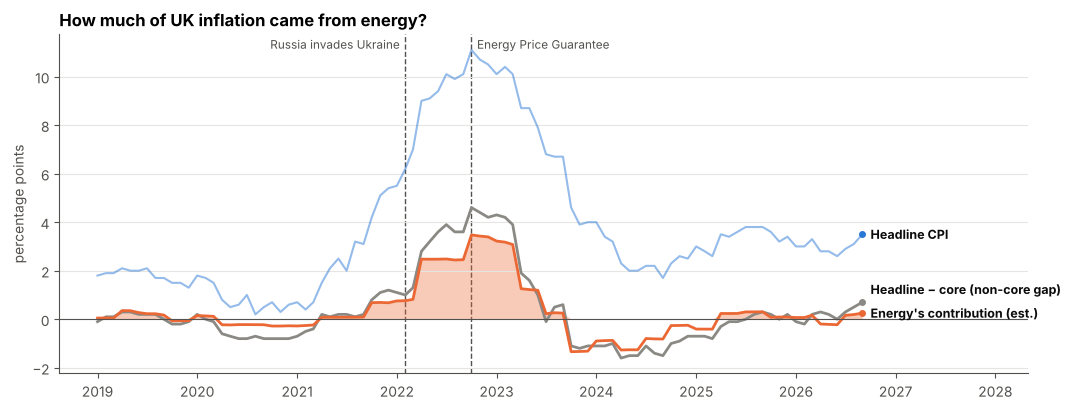

Non-core gap peaked at 4.6 pp (Oct 2022).
Energy's estimated contribution peaked at 3.5 pp (Oct 2022); at the CPI peak it explained about 31% of headline inflation.


In [12]:
def basket_share(weights):
    """Share of the CPI basket each month: the annual weight (per 1,000), price-updated within the year."""
    year = pd.Series(df.index.year, index=df.index)
    jan = lambda s: s.groupby(df.index.year).transform("first")      # January value of each year
    return (year.map(weights) / 1000) * (df.energy_index / jan(df.energy_index)) / (df.cpi_index / jan(df.cpi_index))

df["noncore_gap"] = df.cpi_headline - df.cpi_core
df["energy_contrib"] = basket_share(w_energy).shift(12) * df.cpi_energy

FINDINGS.update(gap_peak=df.noncore_gap.max(), gap_peak_date=df.noncore_gap.idxmax(),
                contrib_peak=df.energy_contrib.max(), contrib_peak_date=df.energy_contrib.idxmax())
FINDINGS["contrib_share_at_cpi_peak"] = df.at[FINDINGS["cpi_peak_date"], "energy_contrib"] / FINDINGS["cpi_peak"]

w = slice("2019-01-01", None)
fig, ax = plt.subplots(figsize=(11, 4.2))
ax.plot(df.loc[w].index, df.loc[w, "cpi_headline"], color=C["headline"], lw=1.5, alpha=0.5)
ax.plot(df.loc[w].index, df.loc[w, "noncore_gap"], color=C["core"])
ax.fill_between(df.loc[w].index, 0, df.loc[w, "energy_contrib"].clip(lower=0), color=C["energy"], alpha=0.35, lw=0)
ax.plot(df.loc[w].index, df.loc[w, "energy_contrib"], color=C["energy"])
ax.axhline(0, color=C["ink2"], lw=0.8)
mark_events(ax, text=True)
ax.set_ylabel("percentage points")
ax.set_title("How much of UK inflation came from energy?")
ax.set_xlim(right=df.index.max() + pd.DateOffset(months=20))
end_labels(ax, [(df.loc[w, "cpi_headline"], "Headline CPI", C["headline"]),
                (df.loc[w, "noncore_gap"], "Headline − core (non-core gap)", C["core"]),
                (df.loc[w, "energy_contrib"], "Energy's contribution (est.)", C["energy"])])
fig.tight_layout()
save(fig, "04_energy_contribution.png")
plt.show()

print(f"Non-core gap peaked at {FINDINGS['gap_peak']:.1f} pp ({FINDINGS['gap_peak_date']:%b %Y}).")
print(f"Energy's estimated contribution peaked at {FINDINGS['contrib_peak']:.1f} pp ({FINDINGS['contrib_peak_date']:%b %Y}); "
      f"at the CPI peak it explained about {FINDINGS['contrib_share_at_cpi_peak']:.0%} of headline inflation.")

**Interpretation.** Household energy is only a few per cent of the CPI basket, yet it added about 3.5 percentage points to inflation in October 2022, roughly a third of the 11.1% peak. Energy explains most of the non-core gap. The remaining 1–1.5 points in 2022–23 is mainly food, which rose as higher energy, fertiliser and transport costs moved through supply chains: a "second-round" effect of the same shock. From late 2023 the effect reversed. Falling bills made energy's contribution negative, which is why headline inflation dropped below core inflation in 2024.

## 7. Policy impact: the Energy Price Guarantee

From October 2022 to June 2023 the government's Energy Price Guarantee (EPG) held a typical household's bill at **£2,500 a year**, against an Ofgem cap that was well above that in all three quarters. Below we work out the saving, and then estimate what CPI would have been if bills had followed the cap instead.

**Saving per household.** (Cap − £2,500) per year × ¼ for each quarter. This is a pro-rata estimate for a household with typical annual use. Real savings were bigger in winter, when more energy is used. The separate £400 Energy Bills Support Scheme is not included.

In [13]:
epg = (df.loc[epg_months, ["cap_gbp"]].groupby(df.loc[epg_months].index.to_period("Q")).first())
epg["epg_gbp"] = EPG_LEVEL
epg["annualised_saving"] = epg.cap_gbp - epg.epg_gbp
epg["saving_in_quarter"] = epg.annualised_saving / 4
epg.index = [f"{p.start_time:%b %Y}–{(p.end_time):%b %Y}" for p in epg.index]
display(epg.round(0))
FINDINGS["epg_saving"] = epg.saving_in_quarter.sum()
print(f"Estimated saving for a typical household over Oct 2022–Jun 2023: £{FINDINGS['epg_saving']:,.0f}")

,cap_gbp,epg_gbp,annualised_saving,saving_in_quarter
Oct 2022–Dec 2022,3549.0,2500,1049.0,262.0
Jan 2023–Mar 2023,4279.0,2500,1779.0,445.0
Apr 2023–Jun 2023,3280.0,2500,780.0,195.0


Estimated saving for a typical household over Oct 2022–Jun 2023: £902


**What would CPI have been without the EPG?** If bills had followed the cap, electricity and gas prices in CPI would have been higher by a factor *k* = cap ÷ £2,500 in each EPG month. Headline CPI moves by roughly that component's **share of the basket** × (*k* − 1). The share starts from the annual basket weight for electricity and gas and is updated within the year for how much energy prices rose relative to everything else. We recompute the annual rate from the counterfactual index. That also captures the knock-on "base effect" a year later, when the counterfactual bills drop out of the comparison.

This is a *first-round* estimate: it ignores any indirect effects, such as firms passing on higher costs or changes in wage demands.

Saved charts/05_epg_counterfactual.png


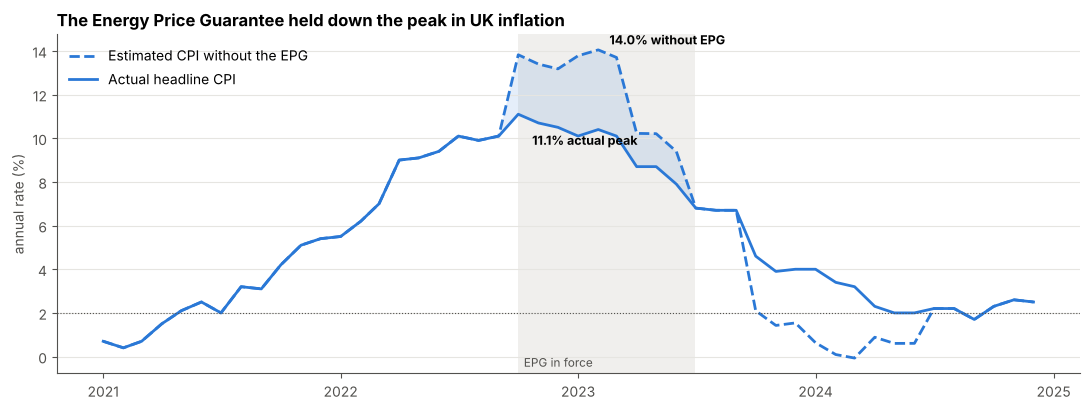

Without the EPG, CPI would have peaked at about 14.0% (Feb 2023) vs an actual peak of 11.1%.
Largest monthly effect: 3.7 pp lower inflation in Jan 2023.


In [14]:
share = basket_share(w_elec_gas)

k = pd.Series(1.0, index=df.index)
k[epg_months] = df.loc[epg_months, "cap_gbp"] / EPG_LEVEL

cf_index = df.cpi_index * (1 + share.fillna(0) * (k - 1))
rate_from_index = df.cpi_index.pct_change(12) * 100
cf_rate = cf_index.pct_change(12) * 100
df["cpi_no_epg"] = df.cpi_headline + (cf_rate - rate_from_index)   # keep the official series, add the gap

FINDINGS["cf_peak"] = df.cpi_no_epg.max()
FINDINGS["cf_peak_date"] = df.cpi_no_epg.idxmax()
FINDINGS["epg_max_effect"] = (df.cpi_no_epg - df.cpi_headline).max()
FINDINGS["epg_max_effect_date"] = (df.cpi_no_epg - df.cpi_headline).idxmax()

w = slice("2021-01-01", "2024-12-01")
fig, ax = plt.subplots(figsize=(11, 4.2))
ax.fill_between(df.loc[w].index, df.loc[w, "cpi_headline"], df.loc[w, "cpi_no_epg"],
                where=df.loc[w, "cpi_no_epg"] >= df.loc[w, "cpi_headline"], color=C["headline"], alpha=0.12, lw=0)
ax.plot(df.loc[w].index, df.loc[w, "cpi_no_epg"], color=C["headline"], ls="--", label="Estimated CPI without the EPG")
ax.plot(df.loc[w].index, df.loc[w, "cpi_headline"], color=C["headline"], label="Actual headline CPI")
ax.axvspan(EPG_START, EPG_END + pd.offsets.MonthEnd(0), color=C["grid"], alpha=0.6, lw=0, zorder=0)
ax.annotate("EPG in force", (EPG_START, 0.02), xycoords=("data", "axes fraction"), xytext=(4, 0),
            textcoords="offset points", fontsize=8.5, color=C["ink2"])
pk = FINDINGS["cf_peak_date"]
ax.annotate(f"{FINDINGS['cf_peak']:.1f}% without EPG", (pk, FINDINGS["cf_peak"]), xytext=(8, 4),
            textcoords="offset points", fontsize=9, fontweight="bold")
ax.annotate(f"{FINDINGS['cpi_peak']:.1f}% actual peak", (FINDINGS["cpi_peak_date"], FINDINGS["cpi_peak"]),
            xytext=(10, -22), textcoords="offset points", ha="left", fontsize=9, fontweight="bold")
ax.axhline(2, color=C["ink2"], lw=0.8, ls=":")
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.set_ylabel("annual rate (%)")
ax.set_title("The Energy Price Guarantee held down the peak in UK inflation")
ax.legend(loc="upper left")
fig.tight_layout()
save(fig, "05_epg_counterfactual.png")
plt.show()

print(f"Without the EPG, CPI would have peaked at about {FINDINGS['cf_peak']:.1f}% ({FINDINGS['cf_peak_date']:%b %Y}) "
      f"vs an actual peak of {FINDINGS['cpi_peak']:.1f}%.")
print(f"Largest monthly effect: {FINDINGS['epg_max_effect']:.1f} pp lower inflation in {FINDINGS['epg_max_effect_date']:%b %Y}.")

**Interpretation.** The EPG saved a typical household about £900 over the nine months, almost half of it in January–March 2023 when the cap peaked at £4,279. Because CPI measures the prices households actually paid, the guarantee lowered measured inflation directly. Without it, our estimate puts the peak at about 14.0% in February 2023 rather than 11.1% in October 2022, with the biggest effect (about 3.7 points) in January 2023. Lower measured inflation also mattered beyond bills: it reduced the uprating of index-linked costs such as some benefits, rail fares and index-linked gilt payments, so part of the EPG's cost was offset elsewhere. The flip side comes a year later: once the guarantee ended, the dashed line drops *below* actual inflation, because the year it is compared against had higher (counterfactual) prices.

## 8. Monetary policy response: Bank Rate vs CPI

Both series are in per cent, so they share one axis. We find the first month after the pandemic in which CPI went above the 2% target, and the first Bank Rate rise after that, and count the months between them. Note that CPI is published about a month after the month it measures, so the Bank was always working with slightly older data than the chart suggests.

Saved charts/06_bank_rate.png


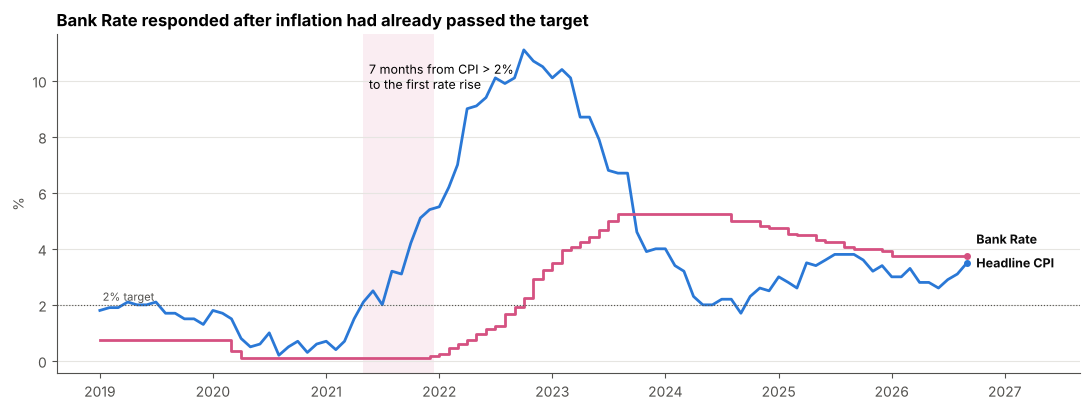

CPI first exceeded 2% in May 2021; first Bank Rate rise: 16 Dec 2021 (7 months later, with CPI at 5.4%).
Bank Rate peaked at 5.25%. The real Bank Rate (Bank Rate − CPI) bottomed at -8.8% in Jul 2022.


In [15]:
post = df.loc["2021-01-01":]
first_above = post.index[post.cpi_headline > 2][0]
rises = bank_daily[bank_daily.diff() > 0]
first_rise = rises[rises.index >= "2021-01-01"].index[0]
gap_months = (first_rise.year - first_above.year) * 12 + (first_rise.month - first_above.month)

df["real_bank_rate"] = df.bank_rate - df.cpi_headline
FINDINGS.update(first_above=first_above, first_rise=first_rise, rate_gap=gap_months,
                bank_peak=bank_daily.max(), real_rate_low=df.real_bank_rate.min(),
                real_rate_low_date=df.real_bank_rate.idxmin(),
                cpi_at_first_rise=df.at[first_rise.to_period("M").to_timestamp(), "cpi_headline"])

w = slice("2019-01-01", None)
fig, ax = plt.subplots(figsize=(11, 4.2))
ax.plot(df.loc[w].index, df.loc[w, "cpi_headline"], color=C["headline"])
ax.step(df.loc[w].index, df.loc[w, "bank_rate"], where="post", color=C["bank"])
ax.axhline(2, color=C["ink2"], lw=0.8, ls=":")
ax.annotate("2% target", (df.loc[w].index[0], 2), xytext=(2, 3), textcoords="offset points", fontsize=8, color=C["ink2"])
ax.axvspan(first_above, first_rise, color=C["bank"], alpha=0.10, lw=0)
ax.annotate(f"{gap_months} months from CPI > 2%\nto the first rate rise", (first_above, 0.92),
            xycoords=("data", "axes fraction"), xytext=(4, 0), textcoords="offset points", fontsize=9, va="top")
ax.set_ylabel("%")
ax.set_title("Bank Rate responded after inflation had already passed the target")
ax.set_xlim(right=df.index.max() + pd.DateOffset(months=12))
end_labels(ax, [(df.loc[w, "cpi_headline"], "Headline CPI", C["headline"]),
                (df.loc[w, "bank_rate"].dropna(), "Bank Rate", C["bank"])])
fig.tight_layout()
save(fig, "06_bank_rate.png")
plt.show()

print(f"CPI first exceeded 2% in {first_above:%b %Y}; first Bank Rate rise: {first_rise:%d %b %Y} "
      f"({gap_months} months later, with CPI at {FINDINGS['cpi_at_first_rise']:.1f}%).")
print(f"Bank Rate peaked at {FINDINGS['bank_peak']:.2f}%. The real Bank Rate (Bank Rate − CPI) bottomed at "
      f"{FINDINGS['real_rate_low']:.1f}% in {FINDINGS['real_rate_low_date']:%b %Y}.")

**Interpretation.** Inflation was above target for seven months, and had reached 5.4%, before the Bank of England first raised rates in December 2021. The Bank argued at first that the energy-driven rise would be temporary, and Bank Rate cannot lower prices set by world gas markets. Its job was to stop higher energy costs feeding into wages and wider prices. Even after a run of rate rises, the **real** Bank Rate (Bank Rate minus CPI) fell to about −8.8% in mid-2022, so savers lost purchasing power quickly. This is a point worth knowing for finance roles (see Section 10).

## 9. Extension: why gas set the price, and would more nuclear have helped?

Saved charts/07_generation_mix.png


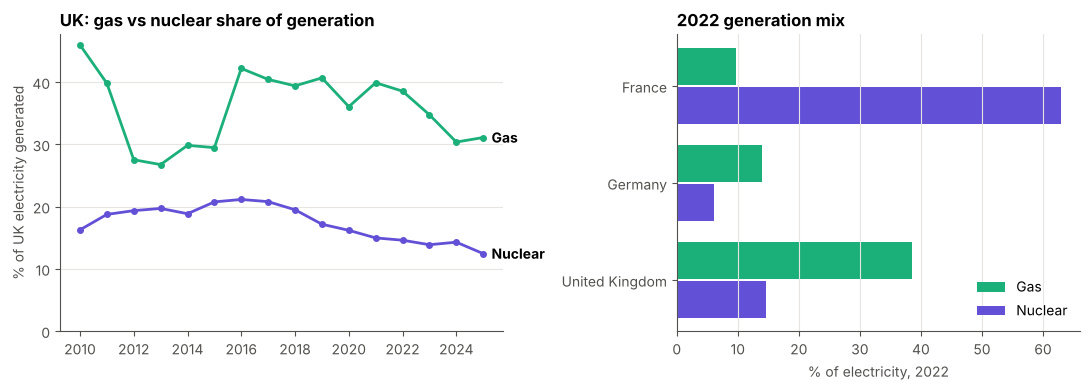

2022: UK gas 39%, UK nuclear 15%, France nuclear 63% of generation.
Saved charts/08_uk_fr_de_energy_inflation.png


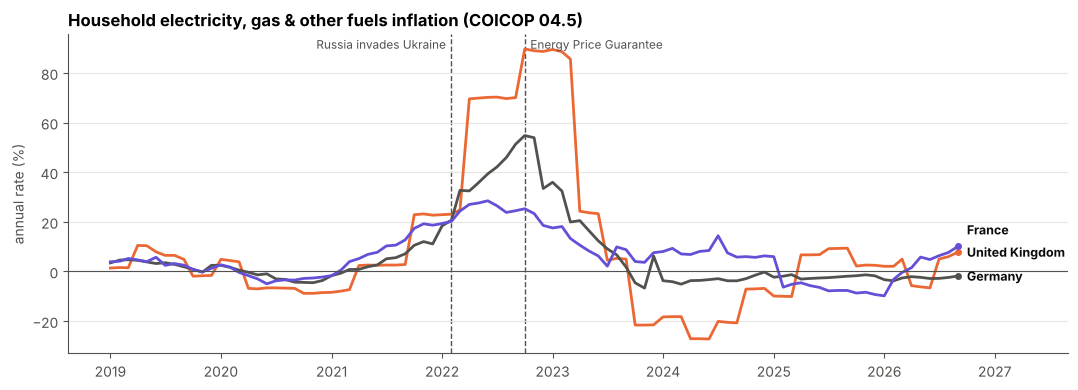

Peak household energy inflation: United Kingdom 90%, France 29%, Germany 55%


In [16]:
if mix is not None:
    uk = mix[(mix.Entity == "United Kingdom") & (mix.Year >= 2010)]
    fig, axes = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw={"width_ratios": [1.1, 1]})
    ax = axes[0]
    ax.plot(uk.Year, uk.gas_share, color=C["gas"], marker="o", ms=4)
    ax.plot(uk.Year, uk.nuclear_share, color=C["cap"], marker="o", ms=4)
    ax.annotate("Gas", (uk.Year.iloc[-1], uk.gas_share.iloc[-1]), xytext=(6, 0), textcoords="offset points", fontweight="bold", va="center")
    ax.annotate("Nuclear", (uk.Year.iloc[-1], uk.nuclear_share.iloc[-1]), xytext=(6, 0), textcoords="offset points", fontweight="bold", va="center")
    ax.set_ylim(0, None)
    ax.set_ylabel("% of UK electricity generated")
    ax.set_title("UK: gas vs nuclear share of generation")
    latest = mix[mix.Year == 2022].set_index("Entity").reindex(["United Kingdom", "Germany", "France"])
    ax = axes[1]
    ypos = np.arange(len(latest))
    ax.barh(ypos + 0.2, latest.gas_share, height=0.38, color=C["gas"], label="Gas")
    ax.barh(ypos - 0.2, latest.nuclear_share, height=0.38, color=C["cap"], label="Nuclear")
    ax.set_yticks(ypos, latest.index)
    ax.set_xlabel("% of electricity, 2022")
    ax.set_title("2022 generation mix")
    ax.grid(axis="x", color=C["grid"]); ax.grid(axis="y", visible=False)
    ax.legend(loc="lower right")
    fig.tight_layout()
    save(fig, "07_generation_mix.png")
    plt.show()
    FINDINGS["uk_gas_share_2022"] = float(latest.at["United Kingdom", "gas_share"])
    FINDINGS["uk_nuclear_share_2022"] = float(latest.at["United Kingdom", "nuclear_share"])
    FINDINGS["fr_nuclear_share_2022"] = float(latest.at["France", "nuclear_share"])
    print(f"2022: UK gas {FINDINGS['uk_gas_share_2022']:.0f}%, UK nuclear {FINDINGS['uk_nuclear_share_2022']:.0f}%, "
          f"France nuclear {FINDINGS['fr_nuclear_share_2022']:.0f}% of generation.")

if eu_energy is not None:
    comp = pd.concat([df.cpi_energy.rename("United Kingdom"), eu_energy], axis=1, sort=True).loc["2019-01-01":]
    fig, ax = plt.subplots(figsize=(11, 4))
    for col, color in [("United Kingdom", C["energy"]), ("Germany", C["ink2"]), ("France", C["cap"])]:
        ax.plot(comp.index, comp[col], color=color)
    ax.axhline(0, color=C["ink2"], lw=0.8)
    mark_events(ax, text=True)
    ax.set_ylabel("annual rate (%)")
    ax.set_title("Household electricity, gas & other fuels inflation (COICOP 04.5)")
    ax.set_xlim(right=comp.index.max() + pd.DateOffset(months=12))
    end_labels(ax, [(comp[c], c, col) for c, col in [("United Kingdom", C["energy"]), ("Germany", C["ink2"]), ("France", C["cap"])]])
    fig.tight_layout()
    save(fig, "08_uk_fr_de_energy_inflation.png")
    plt.show()
    FINDINGS["peak_uk_045"] = comp["United Kingdom"].max()
    FINDINGS["peak_fr_045"] = comp["France"].max()
    FINDINGS["peak_de_045"] = comp["Germany"].max()
    print("Peak household energy inflation: " + ", ".join(f"{c} {comp[c].max():.0f}%" for c in comp.columns))

**Why gas set the price.** Britain's wholesale electricity market pays every generator in a given hour the price of the **marginal** (most expensive) plant needed to meet demand, and for most hours that is a gas-fired power station. So when gas prices rose many times over, wholesale *electricity* prices followed, even though gas made up well under half of the electricity generated. Nuclear, wind and solar were paid the same high price despite their costs not changing. That is how a gas shock became an electricity shock.

**Would more nuclear have helped?** Partly. More nuclear (or any low-carbon capacity) means less gas is burned and fewer hours in which gas sets the price, so the shock would have been smaller. But in hours when gas is still the marginal plant, extra nuclear does not lower the price; consumers only benefit if that nuclear output is sold on fixed-price contracts, such as the Contracts for Difference used for new UK plants. The comparison chart needs care: France generates most of its electricity from nuclear, yet its energy inflation was held down mainly by a state tariff shield, and French nuclear output actually fell in 2022 because of reactor maintenance and corrosion problems. Germany, more dependent on Russian gas, saw a large rise before its own price brakes began in 2023. So the generation mix matters, but policy choices explain much of the difference between countries.

## 10. Conclusion, finance angle and limitations

**Conclusion.** The 2021–23 energy shock passed through to UK inflation in a predictable sequence: wholesale gas → the Ofgem cap after about six months (largely because of how the cap is calculated) → CPI straight away. Household energy alone accounted for about a third of headline inflation at its 11.1% peak, and without the Energy Price Guarantee inflation would probably have reached about 14%. Bank Rate first rose seven months after inflation passed the target, and real interest rates stayed deeply negative through the peak.

**Finance angle.** For businesses, the shock was a margin squeeze: energy-intensive firms (manufacturing, hospitality, food processing) faced input-cost rises that could only partly and slowly be passed on, which shows up in the second-round rise in food and core inflation. For savers and investors, a real Bank Rate far below zero meant cash lost value quickly. That pushed up demand for index-linked products, while the rate rises of 2022–23 brought sharp losses for fixed-rate bond holders.

**Limitations.**
* **Correlation is not causation.** The lag and regression results show timing and co-movement, not proof that gas caused each move; other shocks (post-Covid demand, supply chains, the weaker pound) happened at the same time.
* The counterfactual is first-round only, and the price cap figure is for a "typical" household whose assumed energy use changed in 2020 and 2023.
* Energy's contribution is estimated from weights × rates rather than taken from ONS's official contribution tables.

In [17]:
f = FINDINGS
lines = [
    f"Wholesale gas changes took about {f['lag_gas_cap']} months to show up in the Ofgem price cap, and bill changes reached "
    + ("CPI in the same month" if f['lag_cap_cpi'] == 0 else f"CPI after {f['lag_cap_cpi']} months") + f"; a sustained 10% rise in wholesale gas lifted CPI energy prices by about "
    f"{10 * f['passthrough']:.1f}% within a year.",
    f"Household energy added up to {f['contrib_peak']:.1f} percentage points to inflation ({f['contrib_peak_date']:%b %Y}); "
    f"without the £2,500 Energy Price Guarantee, CPI would have peaked at about {f['cf_peak']:.1f}% instead of "
    f"{f['cpi_peak']:.1f}%, and a typical household saved about £{f['epg_saving']:,.0f}.",
    f"CPI went above the 2% target in {f['first_above']:%B %Y}, {f['rate_gap']} months before the first Bank Rate rise "
    f"({f['first_rise']:%B %Y}); the real Bank Rate fell to {f['real_rate_low']:.1f}%.",
]
print("HEADLINE FINDINGS\n")
for i, l in enumerate(lines, 1):
    print(f"{i}. {l}\n")

HEADLINE FINDINGS

1. Wholesale gas changes took about 6 months to show up in the Ofgem price cap, and bill changes reached CPI in the same month; a sustained 10% rise in wholesale gas lifted CPI energy prices by about 2.0% within a year.

2. Household energy added up to 3.5 percentage points to inflation (Oct 2022); without the £2,500 Energy Price Guarantee, CPI would have peaked at about 14.0% instead of 11.1%, and a typical household saved about £902.

3. CPI went above the 2% target in May 2021, 7 months before the first Bank Rate rise (December 2021); the real Bank Rate fell to -8.8%.



## 11. Outputs: README, requirements and LinkedIn draft

In [18]:
colab_badge = (f"[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)]"
               f"(https://colab.research.google.com/github/{GITHUB_USER}/{REPO}/blob/main/{NOTEBOOK})")
readme = f"""# How much did the 2021–23 energy price shock drive UK inflation?

{colab_badge}

## Question
How much of the 2021–23 rise in UK inflation came from energy, and how long did wholesale gas price rises take to reach household bills (the Ofgem price cap) and CPI?

## Data
Monthly, {df.index.min():%B %Y} to {df.index.max():%B %Y}.
- **ONS** MM23 consumer price inflation: headline CPI (D7G7), core CPI (DKO8), CPI electricity, gas & other fuels (04.5) and basket weights
- **Ofgem** energy price cap (typical dual-fuel bill, `data/ofgem_price_cap.csv`)
- **FRED**: European natural gas (PNGASEUUSDM), Brent crude (DCOILBRENTEU), USD/GBP (DEXUSUK), HICP 04.5 for France and Germany
- **Bank of England**: Bank Rate (IUDBEDR)
- **Our World in Data** (Ember / Energy Institute): electricity generation by source

## Method
1. Converted all series to monthly (month-start) frequency, converted wholesale gas to pence per therm at monthly exchange rates, and forward-filled the price cap.
2. Estimated pass-through lags by correlating year-on-year % changes at lags of 0–12 months (gas → cap, bill → energy CPI).
3. Fitted a 12-month distributed-lag regression of CPI energy prices on wholesale gas to measure the size of the pass-through.
4. Split headline inflation into core, the non-core gap and an estimate of energy's contribution (weight × rate).
5. Calculated the Energy Price Guarantee saving per household and a first-round estimate of CPI without the guarantee.
6. Compared the timing of Bank Rate rises with CPI, and compared the UK with France and Germany.

## Key findings
""" + "\n".join(f"{i}. {l}" for i, l in enumerate(lines, 1)) + f"""

![Timeline](charts/01_timeline.png)

![CPI with and without the Energy Price Guarantee](charts/05_epg_counterfactual.png)

## Limitations
Correlation does not prove causation: other shocks (post-Covid demand, supply chains, sterling) overlapped with the energy shock. The counterfactual is first-round only, and Ofgem's typical-household consumption changed in 2020 and 2023.

## Run it
Open the notebook in Google Colab and choose **Runtime → Run all**. The data downloads automatically; copies are in `data/`.
"""
with open("README.md", "w", encoding="utf-8") as fh:
    fh.write(readme)
with open("requirements.txt", "w") as fh:
    fh.write("pandas>=2.0\nnumpy>=1.24\nmatplotlib>=3.7\nrequests>=2.28\n")

post = f"""How much did the energy price shock drive UK inflation? I used Python to find out.

Using ONS, Ofgem, FRED and Bank of England data, I traced wholesale gas through to household bills and CPI:

- {lines[0]}
- {lines[1]}
- {lines[2]}

The biggest lesson: the Ofgem cap's design built in a delay of several months, and policy (the Energy Price Guarantee) changed the inflation path as much as the market did.

Code and charts: https://github.com/{GITHUB_USER}/{REPO}
#Python #DataAnalysis #Economics #Inflation #Finance"""
with open("linkedin_post_draft.txt", "w", encoding="utf-8") as fh:
    fh.write(post)

with zipfile.ZipFile(f"{REPO}_outputs.zip", "w", zipfile.ZIP_DEFLATED) as z:
    for p in ["README.md", "requirements.txt", "linkedin_post_draft.txt"]:
        z.write(p)
    for folder in [CHART_DIR, DATA_DIR]:
        for name in sorted(os.listdir(folder)):
            z.write(os.path.join(folder, name))
print(f"Wrote README.md, requirements.txt, linkedin_post_draft.txt and {REPO}_outputs.zip")

try:
    from google.colab import files
    files.download(f"{REPO}_outputs.zip")
except ImportError:
    pass

Wrote README.md, requirements.txt, linkedin_post_draft.txt and uk_energy_inflation_outputs.zip
